# Makale Yeniden Üretimi: Açıklanabilir Makine Öğrenmesinde Uyuşmazlık Problemi

**Öğrenci:** Berkay Çongar (20269258007) · **Bölüm:** 32 — Yorumlanabilirlik Yöntemlerinin Değerlendirilmesi ·
**İzlencedeki tür:** Seçenek 2 (Kıyaslama)

**Makale:** Krishna, S., Han, T., Gu, A., Pombra, J., Jabbari, S., Wu, S., ve Lakkaraju, H. (2022).
*The Disagreement Problem in Explainable Machine Learning: A Practitioner's Perspective.* arXiv:2202.01602.

Bölüm 32, gerçek veride açıklamalar için temel gerçeklik olmadığını söyler. Bu makale aynı sorunun pratikteki sonucunu ölçer:
Aynı model ve aynı örnek için farklı açıklama yöntemleri farklı açıklamalar verir. Hangisinin doğru olduğunu söyleyecek bir
temel gerçeklik yoktur.

Defter üç deneyden oluşur:

1. **Deney A, COMPAS:** Makalenin kendi verisinde bulguları yeniden üretmek.
2. **Deney B, Taiwan kredi verisi:** Aynı analizi kendi verimizde tekrarlamak (23 öznitelik, güçlü çoklu bağlantı).
3. **Deney C, uzantı:** Bölüm 32'nin "temel gerçekliğe benzer bir şeyi ancak simüle edilmiş veriyle üretebiliriz" cümlesini
   kullanarak makalenin açık bıraktığı soruyu sormak: Yöntemler anlaşamadığında hangisi haklı?

**Çalıştırma:** Çıktılar `HIZLI = False` ile üretildi (iki çekirdekli bir makinede yaklaşık 7 dakika). Canlı gösterimde
`HIZLI = True` ile aynı analiz daha az örnekle yaklaşık 1,5 dakikada çalışır. Defter Google Colab'da da çalışır:
[Colab'da aç](https://colab.research.google.com/github/mesutpolatgil/xai-dersi-2026/blob/main/2026-guz/32_evaluation-of-interpretability-methods/makale-yeniden-uretim/berkaycongar-20269258007/analiz.ipynb)
(bağlantı, çalışma ders deposuna eklendikten sonra açılır). İlk kod hücresi Colab'da eksik kütüphaneleri kurar; veriler yerelde
yoksa GitHub'dan indirilir.

In [1]:
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules:  # yalnızca Colab'da: eksik kütüphaneleri kur
    eksik = [paket for paket in ("lime", "shap") if importlib.util.find_spec(paket) is None]
    if eksik:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *eksik], check=True)

In [2]:
import time
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

try:  # Jupyter'de tablolar HTML olarak, düz Python'da metin olarak gösterilir
    from IPython.display import display
except ImportError:
    display = print

HIZLI = False   # canlı gösterim için True
RS = 42

AYAR = {
    "lime_ns": 1000 if HIZLI else 3000,         # makale: 3.000 (tablo)
    "ig_adim": 200 if HIZLI else 1500,          # makale: 1.500
    "sg_ornek": 200 if HIZLI else 1500,         # makale: 1.500
    "sg_gurultu": 0.10,                         # makale raporlamıyor: öznitelik aralığının %10'u
    "compas_nokta": 300 if HIZLI else None,     # None = makaledeki gibi tüm test kümesi (1.482)
    "taiwan_nokta": 100 if HIZLI else 300,      # makale German Credit için 200 nokta açıklamış
    "taiwan_kshap_ns": 1000 if HIZLI else 3000, # makale: 3.000 (German Credit)
    "sentetik_nokta": 100 if HIZLI else 200,
}
# Yöntemler, yanıtladıkları soruya göre iki aile hâlinde sıralanır (bkz. bölüm 2.1)
EGIM_AILESI = ["LIME", "Grad", "SmoothGrad"]
KATKI_AILESI = ["KernelSHAP", "Grad×Input", "IG"]
YONTEMLER = EGIM_AILESI + KATKI_AILESI
RASTGELE = "Rastgele"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

SEKIL_KLASORU = Path("sekiller")
SEKIL_KLASORU.mkdir(exist_ok=True)


def sekil_kaydet(ad):
    """Grafiği README ve sunum için 200 dpi PNG olarak da kaydeder."""
    plt.savefig(SEKIL_KLASORU / f"{ad}.png", dpi=200, bbox_inches="tight")

## 1. Uyuşmazlık metrikleri

Makale, iki açıklamanın ($E_a$, $E_b$) ne kadar uyuştuğunu altı metrikle ölçer. $\text{top}_k(E)$, mutlak atıfı en büyük $k$
özniteliktir; $\text{rank}(E, f)$ özniteliğin bu sıralamadaki yeri, $\text{sign}(E, f)$ atıfın işaretidir.

| Metrik | Tanım | Sorduğu soru |
|---|---|---|
| Öznitelik uyumu (FA) | $\lvert \text{top}_k(E_a) \cap \text{top}_k(E_b) \rvert / k$ | En önemli $k$ öznitelik aynı mı? |
| Sıra uyumu (RA) | Aynı sırada aynı öznitelik bulunan konumların oranı | Sıralama da aynı mı? |
| İşaret uyumu (SA) | Ortak top-$k$ özniteliklerden işareti de aynı olanların oranı ($/k$) | Etkinin yönü aynı mı? |
| İşaretli sıra uyumu (SRA) | Hem sırası hem işareti aynı olanların oranı | Sıra ve yön birlikte aynı mı? |
| Sıra korelasyonu (RC) | Tüm özniteliklerde $\lvert E_a \rvert$ ve $\lvert E_b \rvert$ arasında Spearman $\rho$ | Genel önem sıralaması benzer mi? |
| İkili sıra uyumu (PRA) | Öznitelik çiftlerinden göreli sırası aynı olanların oranı | "a, b'den önemli" yargıları tutuyor mu? |

İlk dördü $[0,1]$ arasındadır; RC $[-1,1]$ arasındadır. Hepsinde 1 tam uyum demektir. Makalede açıkça tartışılmayan bir ayrıntıyı da
hesaba katıyoruz: Rastgele iki açıklamanın beklenen uyumu sıfır değildir; örneğin $\mathbb{E}[\text{FA}@k] = k/d$. Bu yüzden her
karşılaştırmaya **rastgele açıklama** satırı ekliyoruz.

In [3]:
def sirala(a):
    return np.argsort(-np.abs(a), kind="stable")


def FA(a, b, k):
    return len(set(sirala(a)[:k]) & set(sirala(b)[:k])) / k


def RA(a, b, k):
    return float(np.mean(sirala(a)[:k] == sirala(b)[:k]))


def SA(a, b, k):
    ortak = set(sirala(a)[:k]) & set(sirala(b)[:k])
    return sum(np.sign(a[j]) == np.sign(b[j]) for j in ortak) / k


def SRA(a, b, k):
    ra, rb = sirala(a)[:k], sirala(b)[:k]
    return float(np.mean((ra == rb) & (np.sign(a[ra]) == np.sign(b[rb]))))


def RC(a, b, k=None):
    return spearmanr(np.abs(a), np.abs(b))[0]


def PRA(a, b, k=None):
    ia, ib = np.abs(a), np.abs(b)
    i, j = np.triu_indices(len(a), 1)
    return float(np.mean(np.sign(ia[i] - ia[j]) == np.sign(ib[i] - ib[j])))


METRIKLER = {"FA": FA, "RA": RA, "SA": SA, "SRA": SRA, "RC": RC, "PRA": PRA}

# Birim testleri: elle hesaplanabilen küçük örnekler
a = np.array([0.5, -0.3, 0.1, 0.0])
assert all(np.isclose(m(a, a, 2), 1) for m in METRIKLER.values())
b = np.array([0.5, 0.3, 0.1, 0.0])                       # ikinci özniteliğin işareti ters
assert FA(a, b, 2) == 1 and RA(a, b, 2) == 1 and SA(a, b, 2) == 0.5 and SRA(a, b, 2) == 0.5
c = np.array([0.0, 0.1, -0.3, 0.5])                      # önem sırası tamamen ters
assert np.isclose(RC(a, c), -1) and PRA(a, c) == 0 and FA(a, c, 2) == 0
print("Metrik birim testleri geçti.")

Metrik birim testleri geçti.


## 2. Açıklama yöntemleri

Makaledeki altı yöntem. Hepsi aynı niceliği açıklar: modelin $P(y = 1 \mid x)$ olasılığı. Gradyan yöntemleri yalnızca
türevlenebilir modellere (lojistik regresyon ve sinir ağı) uygulanır; ağaç modellerinde makaledeki gibi yalnızca LIME ve
KernelSHAP kullanılır. Sinir ağının türevini, scikit-learn ağırlıklarından geri yayılımla kendimiz hesaplıyoruz ve
sonlu farklarla doğruluyoruz.

| Yöntem | Ne hesaplar? | Ayar (makale → bizde) |
|---|---|---|
| LIME | Yerel doğrusal modelin eğimleri | 3.000 örnek → aynı; çekirdek genişliği raporlanmamış → varsayılan |
| KernelSHAP | Shapley katkıları | COMPAS: 128 koalisyon (tam) → aynı; diğerleri 3.000 → aynı |
| Grad | $\nabla_x f(x)$ | — |
| Grad×Input | $x \odot \nabla_x f(x)$ | Girdi, eğitim ortalamasına göre (standartlaştırılmış) |
| IG | $(x - x')\odot \int_0^1 \nabla f(x' + \alpha(x - x'))\,d\alpha$ | 1.500 adım → aynı; taban $x'$ raporlanmamış → eğitim ortalaması |
| SmoothGrad | $\mathbb{E}_{\epsilon}[\nabla f(x + \epsilon)]$ | 1.500 örnek → aynı; gürültü raporlanmamış → aralığın %10'u |

In [4]:
def mlp_gradyan(mlp, X):
    """scikit-learn MLPClassifier (ReLU gizli katmanlar, lojistik çıktı) için P(y=1|x) ve ∂P/∂x."""
    a, onceki = X, []
    for i, (W, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_)):
        z = a @ W + b
        onceki.append(z)
        a = np.maximum(z, 0) if i < len(mlp.coefs_) - 1 else z
    p = 1 / (1 + np.exp(-a[:, 0]))
    g = (p * (1 - p))[:, None]
    for i in range(len(mlp.coefs_) - 1, -1, -1):
        g = g @ mlp.coefs_[i].T
        if i > 0:
            g = g * (onceki[i - 1] > 0)
    return p, g


def gradyan(model, X):
    if isinstance(model, LogisticRegression):
        p = model.predict_proba(X)[:, 1]
        return (p * (1 - p))[:, None] * model.coef_[0][None, :]
    return mlp_gradyan(model, X)[1]


def ig(model, X, adim, parca=20):
    alfa = (np.arange(adim) + 0.5) / adim              # orta nokta Riemann toplamı
    sonuc = np.zeros_like(X)
    for s in range(0, len(X), parca):
        Xc = X[s:s + parca]
        yol = (alfa[:, None, None] * Xc[None]).reshape(-1, X.shape[1])   # taban = 0 (eğitim ortalaması)
        sonuc[s:s + parca] = Xc * gradyan(model, yol).reshape(adim, len(Xc), -1).mean(0)
    return sonuc


def smoothgrad(model, X, n, sigma, tohum=RS, parca=20):
    r = np.random.default_rng(tohum)
    sonuc = np.zeros_like(X)
    for s in range(0, len(X), parca):
        Xc = X[s:s + parca]
        gurultulu = (Xc[None] + r.normal(size=(n, *Xc.shape)) * sigma).reshape(-1, X.shape[1])
        sonuc[s:s + parca] = gradyan(model, gurultulu).reshape(n, len(Xc), -1).mean(0)
    return sonuc


def lime_hepsi(model, X, Xtr, ns):
    ac = LimeTabularExplainer(Xtr, mode="classification", discretize_continuous=False, sample_around_instance=True)
    A = np.zeros_like(X)
    for i, x in enumerate(X):
        ac.random_state = np.random.RandomState(RS + i)
        e = ac.explain_instance(x, model.predict_proba, num_features=X.shape[1], num_samples=ns, labels=(1,))
        for j, v in e.as_map()[1]:
            A[i, j] = v
    return A


def kshap_hepsi(model, X, Xtr, ns):
    np.random.seed(RS)
    ac = shap.KernelExplainer(lambda Z: model.predict_proba(Z)[:, 1], shap.kmeans(Xtr, 25))
    return np.atleast_2d(np.array(ac.shap_values(X, nsamples=ns, l1_reg=False, silent=True)))


def aciklamalar(model, X, Xtr, kshap_ns):
    """Bir model ve açıklanacak örnekler için tüm yöntemlerin atıfları: {yöntem: (n, d)}."""
    sure, A = {}, {}
    turevli = isinstance(model, (LogisticRegression, MLPClassifier))
    # Sözlüğe ekleme sırası = grafiklerdeki sıra: önce eğim ailesi, sonra katkı ailesi
    t0 = time.perf_counter(); A["LIME"] = lime_hepsi(model, X, Xtr, AYAR["lime_ns"]); sure["LIME"] = time.perf_counter() - t0
    if turevli:
        sigma = AYAR["sg_gurultu"] * (np.percentile(Xtr, 99, 0) - np.percentile(Xtr, 1, 0))
        t0 = time.perf_counter()
        A["Grad"] = gradyan(model, X)
        A["SmoothGrad"] = smoothgrad(model, X, AYAR["sg_ornek"], sigma)
        sure["Gradyan yöntemleri"] = time.perf_counter() - t0
    t0 = time.perf_counter(); A["KernelSHAP"] = kshap_hepsi(model, X, Xtr, kshap_ns); sure["KernelSHAP"] = time.perf_counter() - t0
    if turevli:
        t0 = time.perf_counter()
        A["Grad×Input"] = X * A["Grad"]
        A["IG"] = ig(model, X, AYAR["ig_adim"])
        sure["Gradyan yöntemleri"] += time.perf_counter() - t0
    A[RASTGELE] = np.random.default_rng(RS).normal(size=X.shape)
    return A, sure


def gradyan_kontrol(model, X, h=1e-5):
    sayisal = np.zeros_like(X)
    for j in range(X.shape[1]):
        e = np.zeros(X.shape[1]); e[j] = h
        sayisal[:, j] = (model.predict_proba(X + e)[:, 1] - model.predict_proba(X - e)[:, 1]) / (2 * h)
    return np.abs(sayisal - gradyan(model, X)).max()

### 2.1 Birinci ilkelerden bir beklenti: yöntemler iki farklı soruyu yanıtlıyor

Deneylere geçmeden önce en basit modelde, lojistik regresyonda, altı yöntemin ne hesapladığını açıkça yazalım.
$p = \sigma(w^\top x + b)$ ve $x$ eğitim ortalamasına göre ölçülmüş olsun:

| Yöntem | Lojistik regresyonda | $j$. özniteliğin önem sıralamasını belirleyen |
|---|---|---|
| Grad | $p(1-p)\,w_j$ | $\lvert w_j \rvert$ (herkes için aynı) |
| SmoothGrad | $\mathbb{E}_\epsilon[p(1-p)]\,w_j$ | $\lvert w_j \rvert$ |
| LIME | Yerel doğrusal modelin eğimi $\approx c\,w_j$ | $\lvert w_j \rvert$ (yaklaşık) |
| Grad×Input | $p(1-p)\,w_j\,x_j$ | $\lvert w_j x_j \rvert$ |
| IG (taban 0) | $w_j\,x_j \cdot \dfrac{\sigma(w^\top x + b) - \sigma(b)}{w^\top x}$ | $\lvert w_j x_j \rvert$ |
| KernelSHAP | $\approx$ $w_j (x_j - \mathbb{E}[x_j])$ ile orantılı (logit ölçeğinde tam eşit) | $\lvert w_j x_j \rvert$ (yaklaşık) |

İlk üç yöntem **eğimi** ölçer: "Bu özniteliği biraz değiştirirsem tahmin ne kadar değişir?" Son üçü **katkıyı** ölçer:
"Bu kişinin tahminine bu öznitelik ne kadar katkı yaptı?" İki ailenin farkı tek bir çarpandır: $x_j$. Buradan iki tahmin çıkar:

1. **Aile içinde uyum yüksek, aileler arasında düşük olmalı.** Lojistik regresyonda Grad ile SmoothGrad'in, Grad×Input ile
   IG'nin sıralamaları birebir aynı olmalı (RC = 1).
2. **Aileler arasında işaret uyumu yaklaşık yarı yarıya olmalı.** Eğimin işareti $w_j$'ye, katkınınki $w_j x_j$'ye bağlıdır.
   Kişi o öznitelikte ortalamanın altındaysa ($x_j < 0$) iki aile zıt işaret verir.

Makale bazı yöntem çiftlerinin güçlü biçimde uyuştuğunu, bazılarının ise uyuşmadığını gözlemliyor ama bunu bir kuralla açıklamıyor.
Aşağıdaki ısı haritalarında yöntemleri bu iki aileye göre sıralıyoruz; tahmin doğruysa haritalarda iki blok görülmeli.

## 3. Ortak yardımcılar: modeller, uyum matrisleri, ısı haritaları

In [5]:
def modelleri_egit(Xtr, ytr):
    """Makaledeki dört model: LR, 50 ağaçlı GBT ve RF, 4 gizli katmanlı (50-100-100-50, ReLU) sinir ağı."""
    return {
        "LR": LogisticRegression(max_iter=2000).fit(Xtr, ytr),
        "GBT": GradientBoostingClassifier(n_estimators=50, random_state=RS).fit(Xtr, ytr),
        "RF": RandomForestClassifier(n_estimators=50, random_state=RS, n_jobs=-1).fit(Xtr, ytr),
        "NN": MLPClassifier(hidden_layer_sizes=(50, 100, 100, 50), max_iter=500, early_stopping=True,
                            random_state=RS).fit(Xtr, ytr),
    }


def uyum_matrisi(A, metrik, k):
    """Her yöntem çifti için örnekler üzerinden ortalama uyum ve standart hata."""
    adlar = list(A)
    n = len(adlar)
    ort, se = np.eye(n), np.zeros((n, n))
    for i, j in combinations(range(n), 2):
        v = np.array([METRIKLER[metrik](a, b, k) for a, b in zip(A[adlar[i]], A[adlar[j]])], dtype=float)
        ort[i, j] = ort[j, i] = np.nanmean(v)
        se[i, j] = se[j, i] = np.nanstd(v) / np.sqrt(np.sum(~np.isnan(v)))
    return pd.DataFrame(ort, adlar, adlar), pd.DataFrame(se, adlar, adlar)


def isi_haritalari(A, k, baslik, dosya=None):
    fig, axes = plt.subplots(2, 3, figsize=(14, 8.6))
    for ax, metrik in zip(axes.ravel(), METRIKLER):
        M, _ = uyum_matrisi(A, metrik, k)
        alt = -1 if metrik == "RC" else 0
        ax.imshow(M.values, cmap="RdBu" if metrik == "RC" else "viridis", vmin=alt, vmax=1)
        ax.set_xticks(range(len(M)), M.columns, rotation=45, ha="right", fontsize=8.5)
        ax.set_yticks(range(len(M)), M.index, fontsize=8.5)
        for i in range(len(M)):
            for j in range(len(M)):
                v = M.values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                        color="black" if (metrik != "RC" and v > 0.55) or (metrik == "RC" and abs(v) < 0.5) else "white")
        ax.set_title(f"{metrik}" + (f"@{k}" if metrik in ("FA", "RA", "SA", "SRA") else " (tüm öznitelikler)"))
    fig.suptitle(baslik, fontsize=12)
    plt.tight_layout()
    if dosya:
        sekil_kaydet(dosya)
    plt.show()


def ozet_tablo(A, k):
    """Gerçek yöntem çiftlerinin (rastgele hariç) ortalaması ve rastgele açıklamayla uyum (şans düzeyi)."""
    satir = {}
    for metrik in METRIKLER:
        M, _ = uyum_matrisi(A, metrik, k)
        gercek = [y for y in M.index if y != RASTGELE]
        ust = M.loc[gercek, gercek].values[np.triu_indices(len(gercek), 1)]
        satir[metrik] = {"Yöntem çiftleri ort.": np.mean(ust), "En düşük çift": np.min(ust),
                         "Şans düzeyi (rastgele)": M.loc[gercek, RASTGELE].mean()}
    return pd.DataFrame(satir).T.round(3)


def k_tarama(A, k_listesi, metrikler=("FA", "RA", "SA", "SRA")):
    gercek = [y for y in A if y != RASTGELE]
    satirlar = []
    for k in k_listesi:
        for metrik in metrikler:
            M, _ = uyum_matrisi({y: A[y] for y in gercek}, metrik, k)
            satirlar.append({"k": k, "Metrik": metrik, "Ort.": M.values[np.triu_indices(len(gercek), 1)].mean()})
            Ms, _ = uyum_matrisi({gercek[0]: A[gercek[0]], RASTGELE: A[RASTGELE]}, metrik, k)
            satirlar.append({"k": k, "Metrik": metrik + " (şans)", "Ort.": Ms.values[0, 1]})
    return pd.DataFrame(satirlar)


goster = display

## 4. Deney A: COMPAS (makalenin verisi)

**Veri:** ProPublica'nın COMPAS verisi. Makale ön işlemeyi raporlamıyor; ProPublica'nın standart filtrelerini uyguluyoruz
(tutuklama ile değerlendirme arasında en fazla 30 gün, geçerli suç kaydı, "O" düzeyindeki suçlar hariç). Ardından makaledeki
yedi özniteliği kuruyoruz. Etiket, COMPAS'ın risk puanından türetiliyor (`score_text == "High"` → yüksek risk). Bu tanımla
lojistik regresyonun doğruluğu makaledeki 0,84'e denk geliyor.

**Örnek sayısı:** Makale 4.937 sanık ve 1.482 test örneği bildiriyor. Filtreden sonra 6.172 kişi kalıyor; 4.937 tam olarak bunun
%80'i. Makale büyük olasılıkla %80/%20 bölünmüş bir kopyanın eğitim kısmını kullanmış. Aynı sayılara ulaşmak için önce %80'lik
katmanlı bir alt örneklem (4.937 kişi), sonra %70/%30 ayrım (1.482 test) yapıyoruz.

In [6]:
COMPAS_URL = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
compas_yerel = Path("veri/compas-scores-two-years.csv")
ham = pd.read_csv(compas_yerel if compas_yerel.exists() else COMPAS_URL)
c = ham[(ham.days_b_screening_arrest <= 30) & (ham.days_b_screening_arrest >= -30) & (ham.is_recid != -1)
        & (ham.c_charge_degree != "O") & (ham.score_text != "N/A")].copy()
compas = pd.DataFrame({
    "age": c.age,
    "two_year_recid": c.two_year_recid,
    "priors_count": c.priors_count,
    "length_of_stay": (pd.to_datetime(c.c_jail_out) - pd.to_datetime(c.c_jail_in)).dt.days,
    "c_charge_degree": (c.c_charge_degree == "F").astype(int),   # ağır suç = 1
    "sex": (c.sex == "Male").astype(int),
    "race": (c.race == "African-American").astype(int),
})
y_compas = (c.score_text == "High").astype(int).to_numpy()
print(f"Filtre sonrası {len(compas):,} kişi · yüksek risk oranı %{100 * y_compas.mean():.1f}")

X80, _, y80, _ = train_test_split(compas.to_numpy(float), y_compas, train_size=4937, stratify=y_compas, random_state=RS)
Xtr_raw, Xte_raw, ytr_c, yte_c = train_test_split(X80, y80, test_size=0.3, stratify=y80, random_state=RS)
olc_c = StandardScaler().fit(Xtr_raw)
Xtr_c, Xte_c = olc_c.transform(Xtr_raw), olc_c.transform(Xte_raw)
print(f"Kullanılan: {len(X80):,} kişi · eğitim {len(Xtr_c):,} · test {len(Xte_c):,}")

modeller_c = modelleri_egit(Xtr_c, ytr_c)
makale_dogruluk = {"LR": 0.84, "GBT": 0.83, "RF": 0.82, "NN": 0.84}
goster(pd.DataFrame({"Makale": makale_dogruluk,
                     "Bizim": {ad: round(m.score(Xte_c, yte_c), 3) for ad, m in modeller_c.items()}}).T)
print("Sinir ağı gradyanı, sonlu farklarla en büyük fark:", f"{gradyan_kontrol(modeller_c['NN'], Xte_c[:20]):.1e}")

Filtre sonrası 6,172 kişi · yüksek risk oranı %18.5
Kullanılan: 4,937 kişi · eğitim 3,455 · test 1,482


,LR,GBT,RF,NN
Makale,0.840,0.830,0.820,0.840
Bizim,0.842,0.846,0.823,0.844


Sinir ağı gradyanı, sonlu farklarla en büyük fark: 1.4e-11


In [7]:
nokta_c = Xte_c if AYAR["compas_nokta"] is None else Xte_c[:AYAR["compas_nokta"]]
A_compas, sure_c = {}, {}
for ad, m in modeller_c.items():
    A_compas[ad], sure_c[ad] = aciklamalar(m, nokta_c, Xtr_c, kshap_ns=128)
print(f"{len(nokta_c)} test örneği açıklandı. Süreler (sn):",
      {ad: {k: round(v, 1) for k, v in s.items()} for ad, s in sure_c.items()})

1482 test örneği açıklandı. Süreler (sn): {'LR': {'LIME': 4.9, 'Gradyan yöntemleri': 0.3, 'KernelSHAP': 2.1}, 'GBT': {'LIME': 8.4, 'KernelSHAP': 3.2}, 'RF': {'LIME': 28.6, 'KernelSHAP': 42.9}, 'NN': {'LIME': 11.7, 'Gradyan yöntemleri': 16.2, 'KernelSHAP': 9.4}}


### A.1 Isı haritaları: sinir ağı ve lojistik regresyon (k = 5, yedi öznitelik)

Makalenin Şekil 1'i COMPAS için k = 5'teki ikili uyumları gösterir. Aynı ısı haritalarını önce sinir ağı, sonra lojistik
regresyon için çiziyoruz. Son satır ve sütun, rastgele açıklamayla uyumu, yani şans düzeyini gösteriyor.

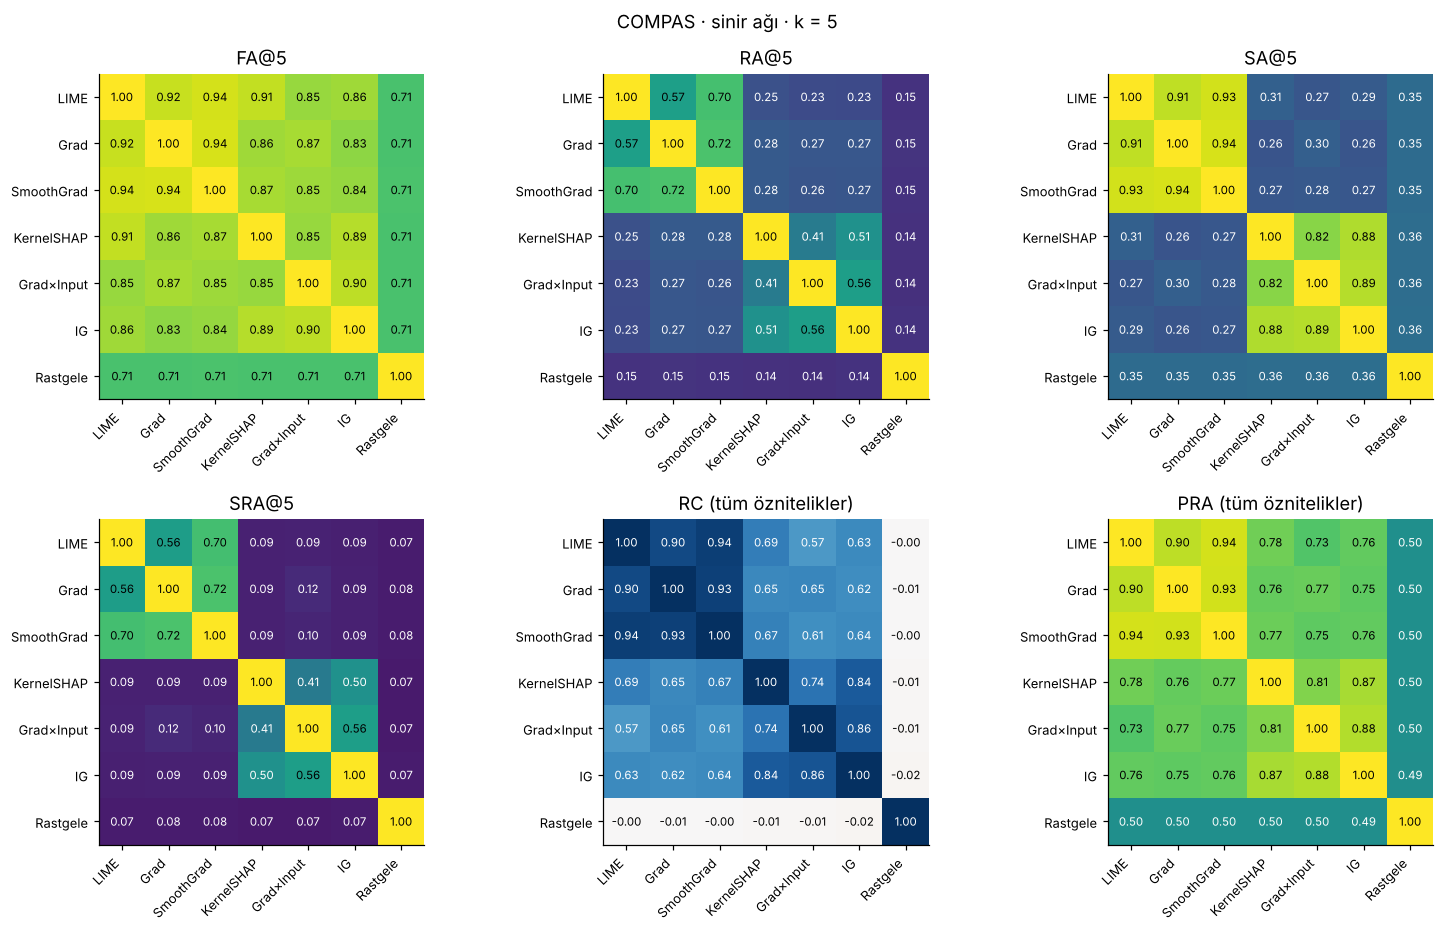

In [8]:
isi_haritalari(A_compas["NN"], 5, "COMPAS · sinir ağı · k = 5", dosya="a1-compas-nn-isi-haritasi")

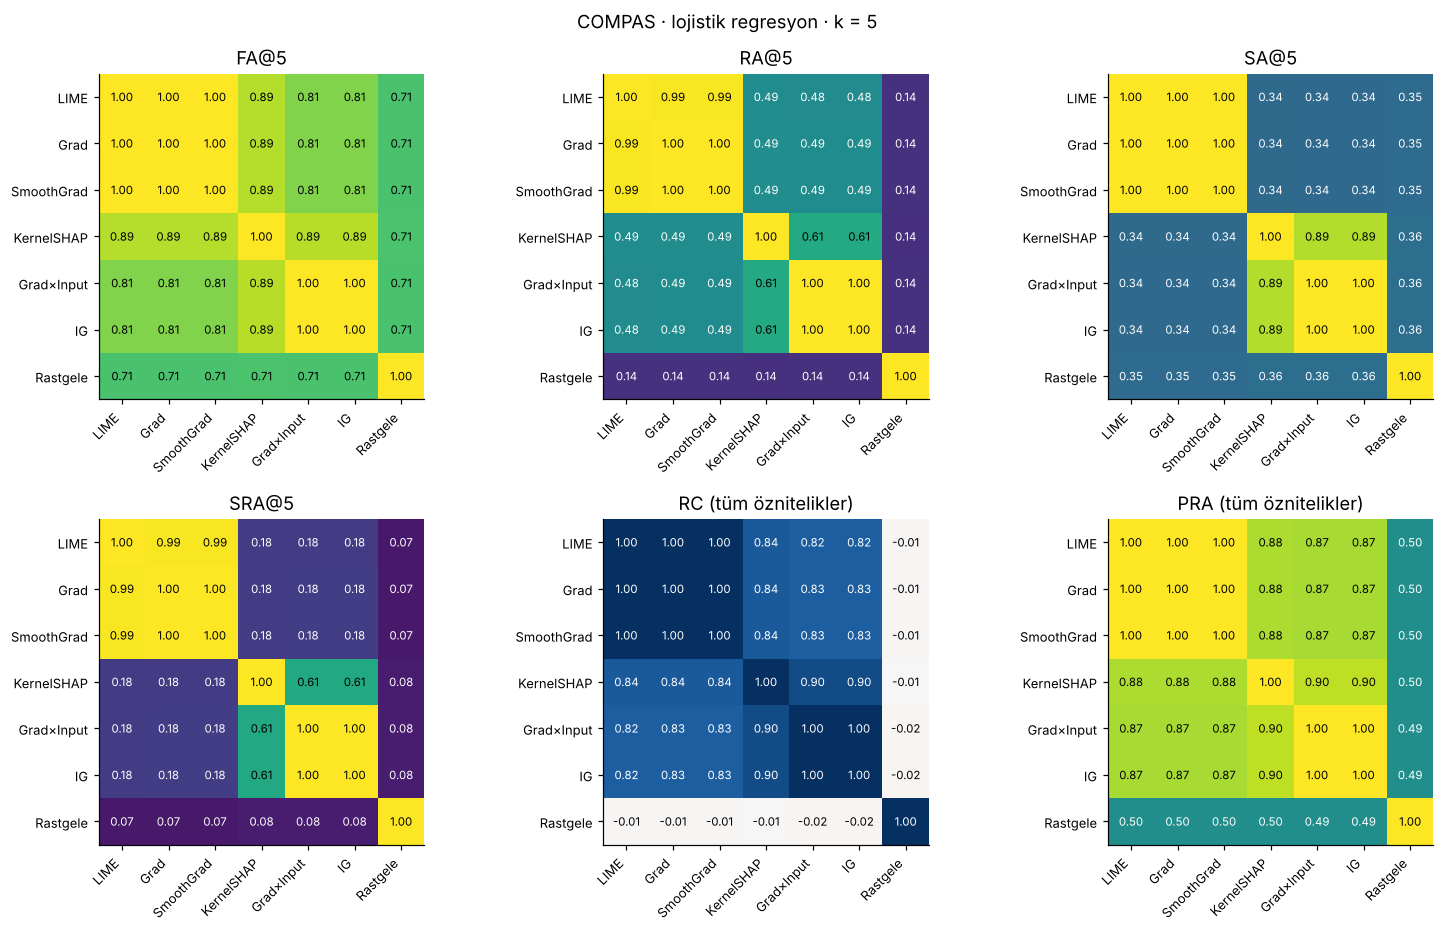

In [9]:
isi_haritalari(A_compas["LR"], 5, "COMPAS · lojistik regresyon · k = 5", dosya="a1-compas-lr-isi-haritasi")

**Yorum (A.1).** Bölüm 2.1'deki tahmin tutuyor: Haritalarda iki blok var. Eğim ailesi (LIME, Grad, SmoothGrad) kendi içinde,
katkı ailesi (KernelSHAP, Grad×Input, IG) kendi içinde uyumlu. İki aile arasındaki uyum ise düşük. Lojistik regresyonda
Grad–SmoothGrad ve Grad×Input–IG çiftlerinin sıra korelasyonu tam 1; türetmenin öngördüğü gibi. İşaret uyumu (SA) aileler
arasında şans düzeyinin bile altına iniyor. Bunun nedeni rastgele bir hata değil: Ortalamanın altında bir değere sahip kişilerde
eğimin işareti ile katkının işareti zıttır.

Bir uyarı: COMPAS'ta FA@5 yüksek görünüyor ama rastgele açıklamanın FA@5'i de yaklaşık 0,71. Yedi öznitelikten beşini seçmek zaten
çoğunu kapsamak demek. Bu yüzden COMPAS'ta FA neredeyse bilgi taşımıyor; asıl ayırt edici olanlar RA ve SRA.

### A.2 Özet: model karmaşıklığı ve ağaç modelleri

Gerçek yöntem çiftlerinin ortalama uyumu ve şans düzeyi. Ağaç modellerinde (GBT, RF) yalnızca LIME ile KernelSHAP karşılaştırılabiliyor.

In [10]:
ozet_c = pd.concat({ad: ozet_tablo(A_compas[ad], 5) for ad in ["LR", "NN"]}, axis=1)
goster(ozet_c)
agac_c = pd.DataFrame({ad: {mt: uyum_matrisi({"LIME": A_compas[ad]["LIME"], "KernelSHAP": A_compas[ad]["KernelSHAP"]}, mt, 5)[0].iloc[0, 1]
                            for mt in METRIKLER} for ad in ["GBT", "RF", "LR", "NN"]}).round(3)
print("LIME ile KernelSHAP arasındaki uyum (k = 5), dört modelde:")
goster(agac_c)

LR                                       \
    Yöntem çiftleri ort. En düşük çift Şans düzeyi (rastgele)   
FA                 0.888         0.811                  0.713   
RA                 0.639         0.483                  0.142   
SA                 0.591         0.343                  0.355   
SRA                0.454         0.178                  0.072   
RC                 0.885         0.825                 -0.013   
PRA                0.910         0.868                  0.496   

                      NN                                       
    Yöntem çiftleri ort. En düşük çift Şans düzeyi (rastgele)  
FA                 0.877         0.830                  0.713  
RA                 0.387         0.226                  0.145  
SA                 0.525         0.262                  0.354  
SRA                0.287         0.089                  0.074  
RC                 0.731         0.572                 -0.009  
PRA                0.811         0.728                  0.497

LIME ile KernelSHAP arasındaki uyum (k = 5), dört modelde:


,GBT,RF,LR,NN
FA,0.949,0.848,0.887,0.907
RA,0.306,0.246,0.485,0.248
SA,0.343,0.330,0.344,0.305
SRA,0.108,0.093,0.178,0.093
RC,0.775,0.579,0.841,0.695
PRA,0.831,0.733,0.878,0.782


**Yorum (A.2).** Makalenin bulgusuyla uyumlu olarak, model karmaşıklaştıkça (lojistik regresyon → sinir ağı) yöntem çiftlerinin
ortalama uyumu düşüyor. Ağaç modellerinde yalnızca LIME ile KernelSHAP karşılaştırılabiliyor; bu ikisi farklı ailelerden geldiği için
sıra ve işaret uyumları her modelde düşük. En düşük değerler rastgele ormanda.

### A.3 k arttıkça uyum

Makalenin Şekil 2'si: Sıra uyumu (RA) ve işaretli sıra uyumu (SRA) k arttıkça düşüyor. Kesikli çizgiler şans düzeyini gösteriyor.

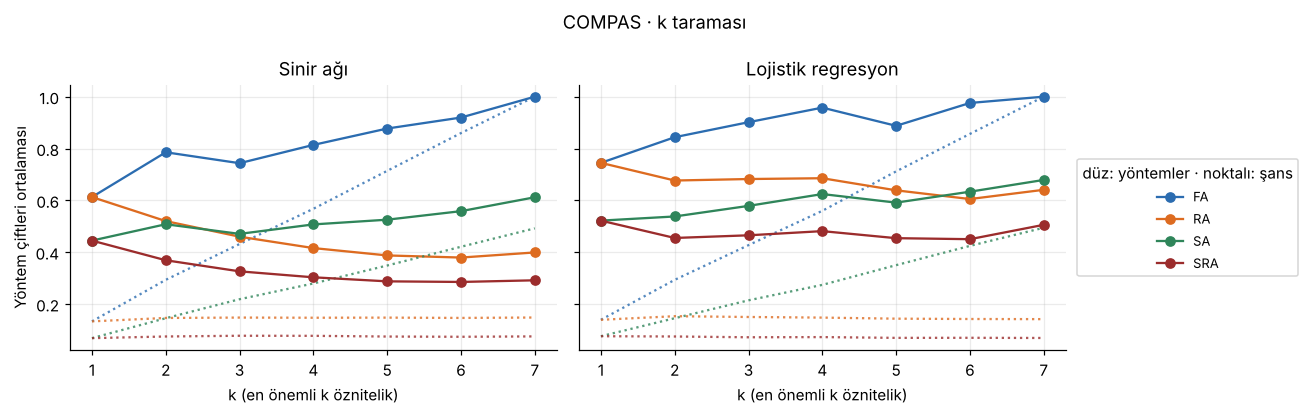

In [11]:
def k_cizimi(A_dict, k_listesi, baslik, dosya=None):
    fig, axes = plt.subplots(1, len(A_dict), figsize=(6 * len(A_dict), 3.8), sharey=True)
    axes = np.atleast_1d(axes)
    renk = {"FA": "#2B6CB0", "RA": "#DD6B20", "SA": "#2F855A", "SRA": "#9B2C2C"}
    for ax, (ad, A) in zip(axes, A_dict.items()):
        df_k = k_tarama(A, k_listesi)
        for m in renk:
            v = df_k[df_k.Metrik == m]
            ax.plot(v.k, v["Ort."], "o-", color=renk[m], label=m)
            v = df_k[df_k.Metrik == m + " (şans)"]
            ax.plot(v.k, v["Ort."], ":", color=renk[m], alpha=0.8)
        ax.set_title(ad)
        ax.set_xlabel("k (en önemli k öznitelik)")
        ax.grid(alpha=0.25)
    axes[0].set_ylabel("Yöntem çiftleri ortalaması")
    axes[-1].legend(title="düz: yöntemler · noktalı: şans", fontsize=8.5, loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.suptitle(baslik)
    plt.tight_layout()
    if dosya:
        sekil_kaydet(dosya)
    plt.show()


k_cizimi({"Sinir ağı": A_compas["NN"], "Lojistik regresyon": A_compas["LR"]}, range(1, 8), "COMPAS · k taraması", dosya="a3-compas-k-taramasi")

**Yorum (A.3).** RA ve SRA, k arttıkça düşüyor; bu, makalenin Şekil 2'sindeki bulgunun aynısı. Önemsiz özniteliklerin sırası,
önemli olanlarınkinden daha keyfî. FA ise k arttıkça yükseliyor ama noktalı çizgiye bakınca bunun büyük kısmının şans düzeyinin
($k/d$) artmasından geldiği görülüyor: k = 7'de iki açıklama da tüm öznitelikleri kapsadığı için FA zorunlu olarak 1 oluyor.

## 5. Deney B: Taiwan kredi kartı temerrüdü (kendi verimiz)

Uygulama klasöründeki veriyi aynı temizlik adımlarıyla kullanıyoruz: 30.000 müşteri, 23 öznitelik. Makalenin German Credit
verisindeki gibi 3.000 KernelSHAP örneği kullanıyor ve rastgele seçilmiş test örneklerini açıklıyoruz. Makalenin hipotezi:
Öznitelik sayısı arttıkça uyuşmazlık artar. Bizim ek hipotezimiz: Güçlü çoklu bağlantı uyuşmazlığı daha da artırır, çünkü
modeller aynı bilgiyi birbirine bağlı öznitelikler arasında keyfî biçimde paylaştırabilir.

In [12]:
TAIWAN_YOLLARI = [Path("../../uygulama/berkaycongar-20269258007/veri/default_of_credit_card_clients.csv"),
                  Path("veri/default_of_credit_card_clients.csv")]
TAIWAN_URLLERI = [  # yerel kopya yoksa (ör. Colab): önce ders deposundaki CSV, o da yoksa UCI dosyasının GitHub'daki kopyası
    "https://raw.githubusercontent.com/mesutpolatgil/xai-dersi-2026/main/2026-guz/32_evaluation-of-interpretability-methods/"
    "uygulama/berkaycongar-20269258007/veri/default_of_credit_card_clients.csv",
    "https://raw.githubusercontent.com/jphall663/interpretable_machine_learning_with_python/master/default_of_credit_card_clients.xls",
]


def taiwan_oku():
    yol = next((p for p in TAIWAN_YOLLARI if p.exists()), None)
    if yol:
        return pd.read_csv(yol)
    for url in TAIWAN_URLLERI:
        try:
            return pd.read_excel(url, header=1) if url.endswith(".xls") else pd.read_csv(url)
        except Exception as hata:  # bir kaynak erişilemezse sıradakini dene
            print("Kaynak okunamadı:", url, "→", hata)
    raise FileNotFoundError("Taiwan verisi bulunamadı.")


tw = taiwan_oku()
tw = tw.drop(columns="ID").rename(columns={"PAY_0": "PAY_1", "default payment next month": "TEMERRUT"})
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
tw["MARRIAGE"] = tw["MARRIAGE"].replace({0: 3})
y_tw = tw.pop("TEMERRUT").to_numpy()
OZN_TW = list(tw.columns)

Xtr_raw, Xte_raw, ytr_t, yte_t = train_test_split(tw.to_numpy(float), y_tw, test_size=0.3, stratify=y_tw, random_state=RS)
olc_t = StandardScaler().fit(Xtr_raw)
Xtr_t, Xte_t = olc_t.transform(Xtr_raw), olc_t.transform(Xte_raw)
modeller_t = modelleri_egit(Xtr_t, ytr_t)
goster(pd.DataFrame({"Doğruluk": {ad: round(m.score(Xte_t, yte_t), 3) for ad, m in modeller_t.items()}}).T)
print("Sinir ağı gradyanı, sonlu farklarla en büyük fark:", f"{gradyan_kontrol(modeller_t['NN'], Xte_t[:20]):.1e}")

secim = np.random.default_rng(RS).choice(len(Xte_t), AYAR["taiwan_nokta"], replace=False)
nokta_t = Xte_t[secim]
A_tw, sure_t = {}, {}
for ad, m in modeller_t.items():
    A_tw[ad], sure_t[ad] = aciklamalar(m, nokta_t, Xtr_t, kshap_ns=AYAR["taiwan_kshap_ns"])
print(f"{len(nokta_t)} test örneği açıklandı. Süreler (sn):",
      {ad: {k: round(v, 1) for k, v in s.items()} for ad, s in sure_t.items()})

,LR,GBT,RF,NN
Doğruluk,0.808,0.818,0.815,0.816


Sinir ağı gradyanı, sonlu farklarla en büyük fark: 1.3e-11


300 test örneği açıklandı. Süreler (sn): {'LR': {'LIME': 1.9, 'Gradyan yöntemleri': 0.2, 'KernelSHAP': 6.6}, 'GBT': {'LIME': 2.5, 'KernelSHAP': 14.9}, 'RF': {'LIME': 8.6, 'KernelSHAP': 45.6}, 'NN': {'LIME': 3.0, 'Gradyan yöntemleri': 3.4, 'KernelSHAP': 49.1}}


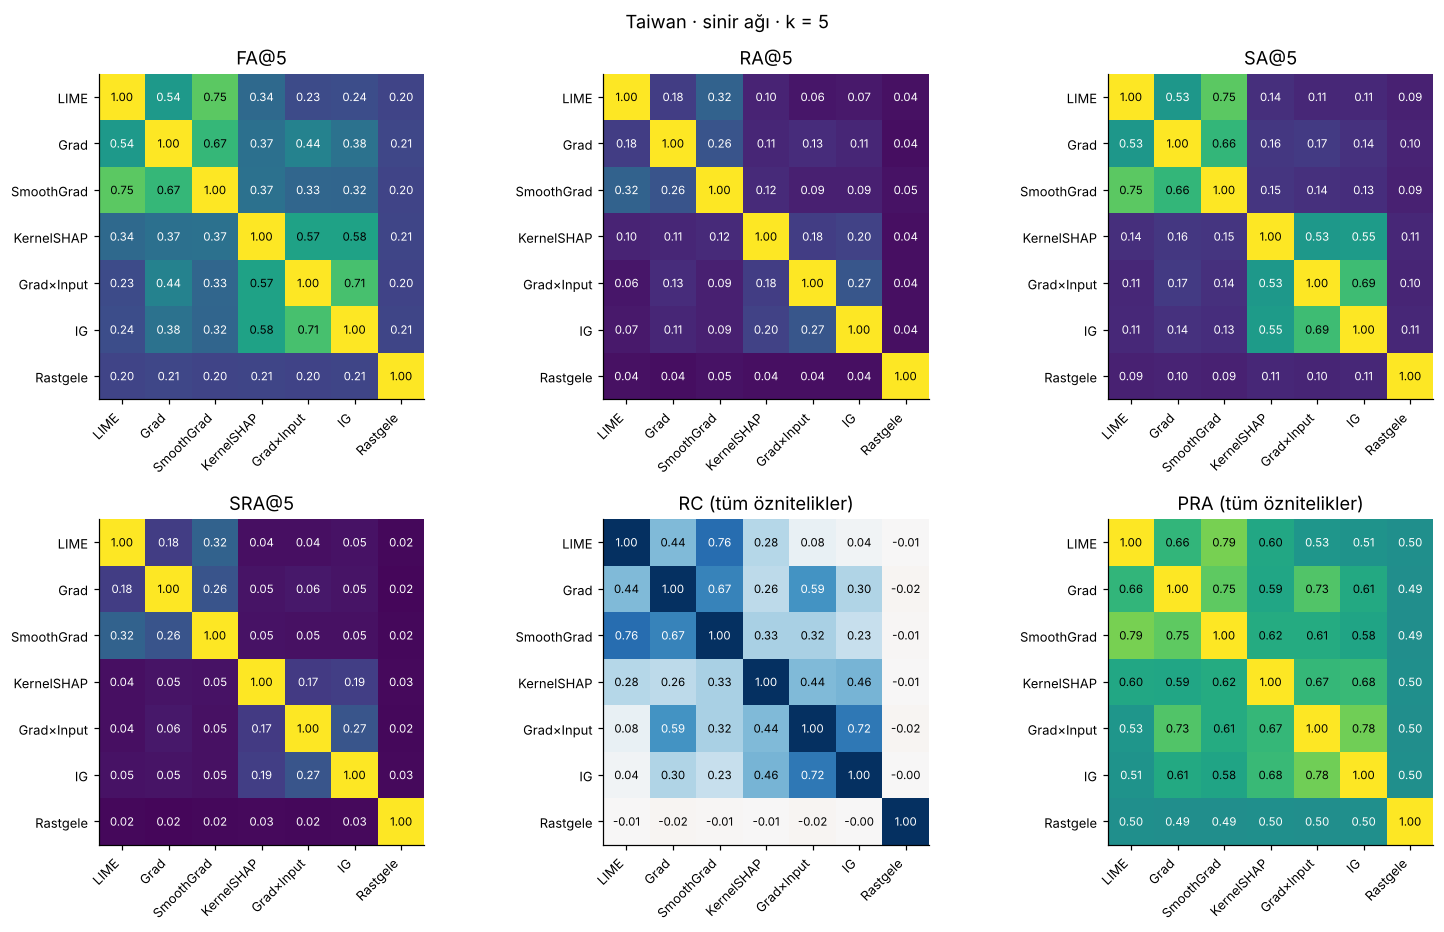

In [13]:
isi_haritalari(A_tw["NN"], 5, "Taiwan · sinir ağı · k = 5", dosya="b1-taiwan-nn-isi-haritasi")

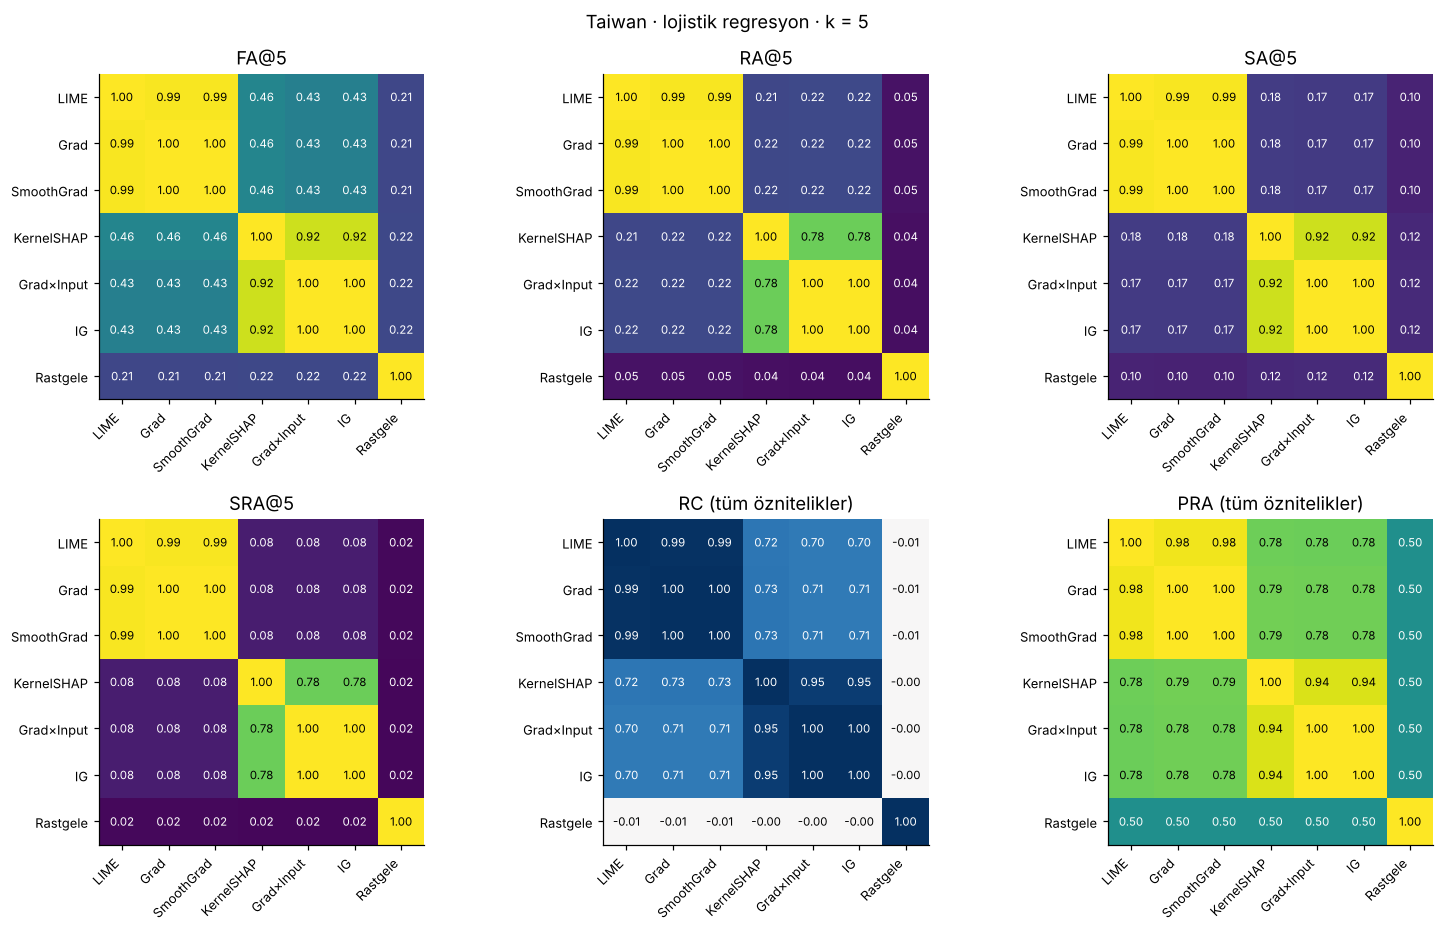

In [14]:
isi_haritalari(A_tw["LR"], 5, "Taiwan · lojistik regresyon · k = 5", dosya="b1-taiwan-lr-isi-haritasi")

In [15]:
ozet_t = pd.concat({ad: ozet_tablo(A_tw[ad], 5) for ad in ["LR", "NN"]}, axis=1)
goster(ozet_t)
agac_t = pd.DataFrame({ad: {mt: uyum_matrisi({"LIME": A_tw[ad]["LIME"], "KernelSHAP": A_tw[ad]["KernelSHAP"]}, mt, 5)[0].iloc[0, 1]
                            for mt in METRIKLER} for ad in ["GBT", "RF", "LR", "NN"]}).round(3)
print("LIME ile KernelSHAP arasındaki uyum (k = 5), dört modelde:")
goster(agac_t)

LR                                       \
    Yöntem çiftleri ort. En düşük çift Şans düzeyi (rastgele)   
FA                 0.653         0.431                  0.215   
RA                 0.500         0.215                  0.044   
SA                 0.492         0.169                  0.107   
SRA                0.417         0.079                  0.020   
RC                 0.821         0.704                 -0.005   
PRA                0.858         0.776                  0.498   

                      NN                                       
    Yöntem çiftleri ort. En düşük çift Şans düzeyi (rastgele)  
FA                 0.455         0.227                  0.206  
RA                 0.152         0.061                  0.042  
SA                 0.332         0.110                  0.102  
SRA                0.122         0.042                  0.022  
RC                 0.395         0.039                 -0.011  
PRA                0.647         0.513                  0.496

LIME ile KernelSHAP arasındaki uyum (k = 5), dört modelde:


,GBT,RF,LR,NN
FA,0.430,0.378,0.455,0.341
RA,0.169,0.096,0.215,0.100
SA,0.125,0.106,0.176,0.137
SRA,0.031,0.027,0.079,0.043
RC,0.409,0.256,0.722,0.282
PRA,0.648,0.591,0.781,0.599


**Yorum (B.1).** Kendi verimizde de iki aile bloğu görülüyor. Ancak 23 öznitelikli ve çoklu bağlantılı Taiwan verisinde uyum,
özellikle sinir ağında, COMPAS'tan belirgin biçimde düşük. Lojistik regresyonda aile içi uyum yine tam; uyuşmazlık aileler
arasında. Sinir ağında ise aile içi uyum da bozuluyor: Doğrusal olmayan bir modelde eğim noktadan noktaya değiştiği için Grad ile
SmoothGrad artık aynı şeyi göstermiyor.

### B.2 COMPAS ile Taiwan karşılaştırması: aynı göreli k'da uyum

İki veri setinin öznitelik sayısı farklı (7 ve 23). Makale German Credit için k'yı özniteliklerin %25, %50, %75 ve %100'ü olarak
alır; biz de aynısını yapıyoruz. Şans düzeyini (noktalı) de çizdiğimiz için, uyuşmazlığın ne kadarının yalnızca
"daha çok öznitelik arasından seçim yapmaktan" kaynaklandığını görebiliyoruz.

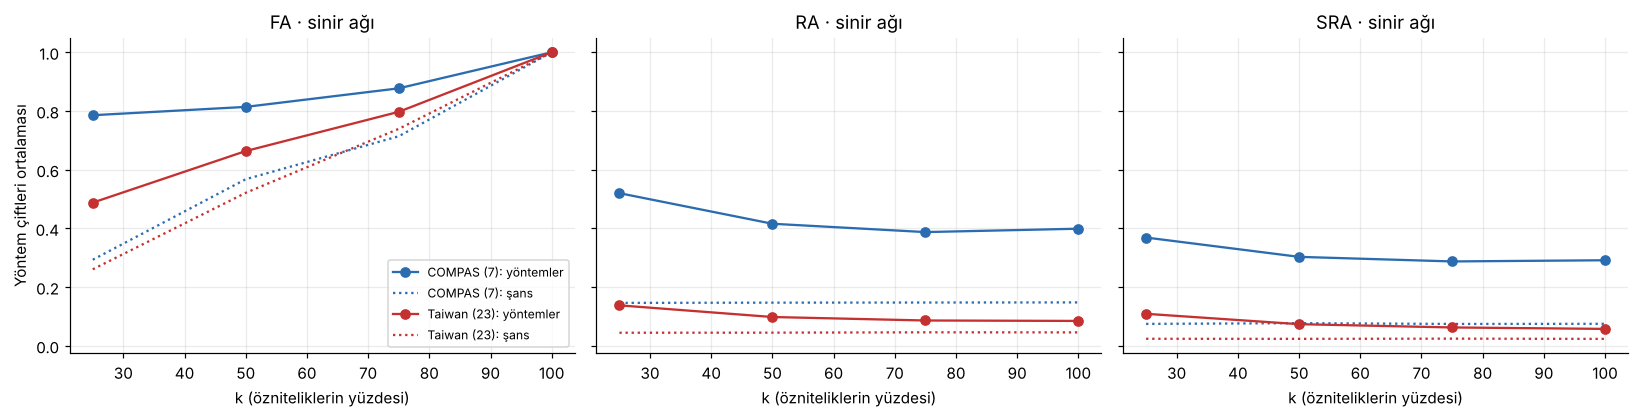

In [16]:
def goreli_k(A, d):
    satir = []
    for oran in (0.25, 0.5, 0.75, 1.0):
        k = max(1, int(round(oran * d)))
        df_k = k_tarama(A, [k], metrikler=("FA", "RA", "SRA"))
        for _, r in df_k.iterrows():
            satir.append({"oran": oran, "Metrik": r.Metrik, "Ort.": r["Ort."]})
    return pd.DataFrame(satir)


fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, metrik in zip(axes, ["FA", "RA", "SRA"]):
    for (veri, A, d_, renk) in [("COMPAS (7)", A_compas["NN"], 7, "#2B6CB0"), ("Taiwan (23)", A_tw["NN"], 23, "#C53030")]:
        g = goreli_k(A, d_)
        v = g[g.Metrik == metrik]
        ax.plot(v.oran * 100, v["Ort."], "o-", color=renk, label=f"{veri}: yöntemler")
        v = g[g.Metrik == metrik + " (şans)"]
        ax.plot(v.oran * 100, v["Ort."], ":", color=renk, label=f"{veri}: şans")
    ax.set_title(f"{metrik} · sinir ağı")
    ax.set_xlabel("k (özniteliklerin yüzdesi)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Yöntem çiftleri ortalaması")
axes[0].legend(fontsize=8)
plt.tight_layout()
sekil_kaydet("b2-compas-taiwan-goreli-k")
plt.show()

**Yorum (B.2).** Makalenin "öznitelik sayısı arttıkça uyuşmazlık artar" iddiası kendi verimizde doğrulanıyor, ama bir şerhle:
Mutlak değerlerdeki farkın bir kısmı metriklerin şans düzeyinin öznitelik sayısına bağlı olmasından geliyor. Şans düzeyini
hesaba katınca bile Taiwan'daki sinir ağında sıra uyumu çok düşük: İlk beş sıradan ortalama birinden azı iki yöntemde aynı
(RA@5 ≈ 0,15; şans düzeyi ≈ 0,04). Yani bu modelde "en önemli özniteliklerin sırası" konusunda yöntemler pratikte anlaşmıyor.

## 6. Deney C (uzantı): Temel gerçekliği bildiğimizde hangi yöntem haklı?

Makale yöntemlerin anlaşmadığını gösteriyor ama hangisinin haklı olduğunu söyleyemiyor; gerçek veride temel gerçeklik yok.
Bölüm 32'nin önerdiği yoldan gidiyoruz: Veriyi kendimiz üretiyoruz, böylece "doğru açıklama" biliniyor.

**Veri üretim süreci:** 8 öznitelik, $x \sim N(0, \Sigma)$; $\text{logit}\,P(y=1\mid x) = \beta^\top x$,
$\beta = (1{,}5;\ -1{,}2;\ 1{,}0;\ -0{,}8;\ 0{,}6;\ 0;\ 0;\ 0)$. Son üç özniteliğin gerçek etkisi sıfır. Ancak $x_6$, $x_1$ ile;
$x_7$ de $x_2$ ile $\rho$ kadar ilişkili. Bu yüzden, gerçekte hiçbir etkisi olmasa da $x_6$ ile $x_7$, sonucu yordamaya yardımcı
*görünebilir*. Bu öznitelikleri "sahte vekil" diye adlandırıyoruz. (Defterde öznitelikler $x_1..x_8$ diye numaralanıyor.)

"Doğru açıklama" tek bir şey değil. İki farklı soru, iki farklı temel gerçeklik verir:

* **Katkı sorusu:** "Bu kişinin tahminine hangi öznitelik ne kadar katkı yaptı?" → $\beta_j\, x_j$ (logit ölçeğinde,
  ortalamaya göre). SHAP, Grad×Input ve IG bu soruyu sorar.
* **Duyarlılık sorusu:** "Bu özniteliği biraz değiştirirsem tahmin ne kadar değişir?" → $\beta_j$ (her kişi için aynı).
  Grad, SmoothGrad ve LIME'ın eğimleri bu soruyu sorar.

In [17]:
BETA = np.array([1.5, -1.2, 1.0, -0.8, 0.6, 0.0, 0.0, 0.0])
OZN_S = [f"x{j + 1}" for j in range(8)]
SAHTE = [5, 6]   # x6 ve x7: gerçek etkisi sıfır, x1 ve x2 ile ilişkili


def sentetik(n, rho, tohum):
    r = np.random.default_rng(tohum)
    S = np.eye(8)
    S[0, 5] = S[5, 0] = rho
    S[1, 6] = S[6, 1] = rho
    X = r.multivariate_normal(np.zeros(8), S, size=n)
    y = (r.random(n) < 1 / (1 + np.exp(-X @ BETA))).astype(int)
    return X, y


def gercege_uyum(A, X, k=3):
    """Her yöntemin iki temel gerçeklikle (katkı, duyarlılık) uyumu: FA@k ve RC ortalamaları."""
    katki = X * BETA
    duyarlilik = np.tile(BETA, (len(X), 1))
    satir = {}
    for y, E in A.items():
        satir[y] = {
            "Katkı FA@3": np.mean([FA(e, t, k) for e, t in zip(E, katki)]),
            "Katkı RC": np.nanmean([RC(e, t) for e, t in zip(E, katki)]),
            "Duyarlılık FA@3": np.mean([FA(e, t, k) for e, t in zip(E, duyarlilik)]),
            "Duyarlılık RC": np.nanmean([RC(e, t) for e, t in zip(E, duyarlilik)]),
            "Sahte vekillerin payı": np.mean(np.abs(E[:, SAHTE]).sum(1) / (np.abs(E).sum(1) + 1e-12)),
        }
    return pd.DataFrame(satir).T


Xs, ys = sentetik(1000, 0.0, RS)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=RS)
nn_s = MLPClassifier(hidden_layer_sizes=(50, 100, 100, 50), max_iter=500, early_stopping=True, random_state=RS).fit(Xs_tr, ys_tr)
lr_s = LogisticRegression(max_iter=2000).fit(Xs_tr, ys_tr)
nokta_s = Xs_te[:AYAR["sentetik_nokta"]]
A_s = {"LR": aciklamalar(lr_s, nokta_s, Xs_tr, kshap_ns=256)[0], "NN": aciklamalar(nn_s, nokta_s, Xs_tr, kshap_ns=256)[0]}
uyum_s = {ad: gercege_uyum(A, nokta_s) for ad, A in A_s.items()}
goster(pd.concat(uyum_s, axis=1).round(3))

LR                                         \
           Katkı FA@3 Katkı RC Duyarlılık FA@3 Duyarlılık RC   
LIME            0.690    0.807           0.995         0.976   
Grad            0.690    0.807           1.000         0.976   
SmoothGrad      0.690    0.807           1.000         0.976   
KernelSHAP      0.938    0.896           0.652         0.694   
Grad×Input      0.955    0.909           0.657         0.705   
IG              0.955    0.909           0.657         0.705   
Rastgele        0.365   -0.030           0.378        -0.031   

                                         NN                           \
           Sahte vekillerin payı Katkı FA@3 Katkı RC Duyarlılık FA@3   
LIME                       0.033      0.663    0.788           0.830   
Grad                       0.031      0.643    0.707           0.742   
SmoothGrad                 0.031      0.652    0.766           0.807   
KernelSHAP                 0.032      0.910    0.882           0.640   
Grad×Input                 0.033      0.790    0.705           0.562   
IG                         0.033      0.885    0.851           0.635   
Rastgele                   0.259      0.365   -0.030           0.378   

                                                
           Duyarlılık RC Sahte vekillerin payı  
LIME               0.919                 0.043  
Grad               0.799                 0.098  
SmoothGrad         0.880                 0.067  
KernelSHAP         0.674                 0.033  
Grad×Input         0.488                 0.100  
IG                 0.637                 0.056  
Rastgele          -0.031                 0.259

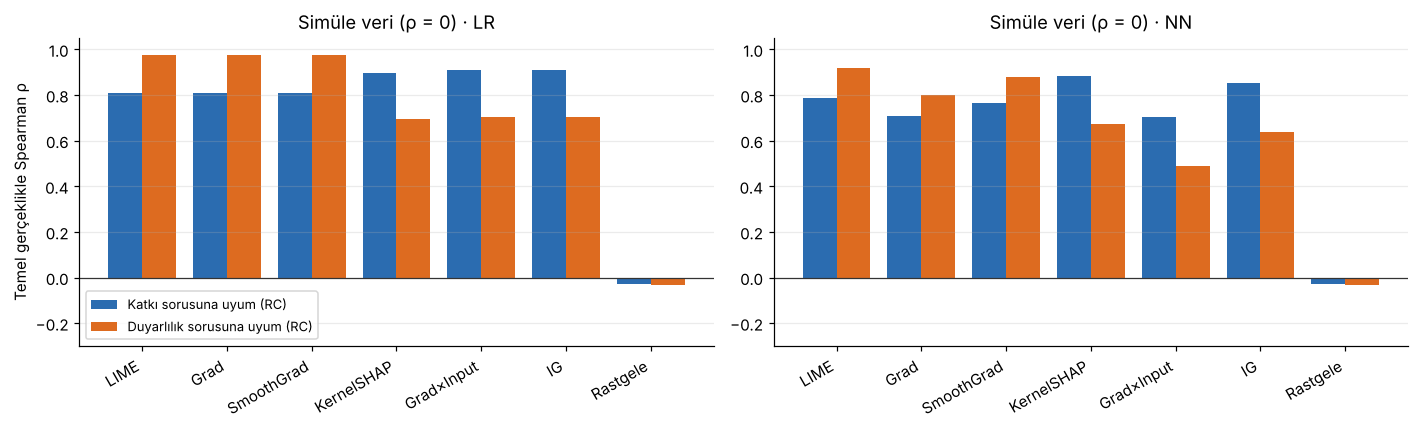

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
yontem_sira = YONTEMLER + [RASTGELE]   # önce eğim, sonra katkı ailesi
for ax, ad in zip(axes, ["LR", "NN"]):
    U = uyum_s[ad].loc[yontem_sira]
    xpos = np.arange(len(U))
    ax.bar(xpos - 0.2, U["Katkı RC"], 0.4, color="#2B6CB0", label="Katkı sorusuna uyum (RC)")
    ax.bar(xpos + 0.2, U["Duyarlılık RC"], 0.4, color="#DD6B20", label="Duyarlılık sorusuna uyum (RC)")
    ax.set_xticks(xpos, U.index, rotation=30, ha="right")
    ax.axhline(0, color="#333", lw=0.8)
    ax.set_ylim(-0.3, 1.05)
    ax.set_title(f"Simüle veri (ρ = 0) · {ad}")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Temel gerçeklikle Spearman ρ")
axes[0].legend(fontsize=8.5, loc="lower left")
plt.tight_layout()
sekil_kaydet("c1-sentetik-iki-soru")
plt.show()

**Yorum (C.1).** Temel gerçekliği bildiğimizde "hangi yöntem haklı?" sorusunun cevabı "hangi soruyu sorduğunuza bağlı" oluyor.
Eğim ailesi, duyarlılık sorusunun gerçeğiyle; katkı ailesi, katkı sorusunun gerçeğiyle daha iyi örtüşüyor. Bu durum lojistik
regresyonda çok net, sinir ağında daha az keskin. Dolayısıyla makalenin ölçtüğü uyuşmazlığın önemli bir kısmı yöntemlerin hatası
değil, farklı sorulara verilen doğru cevaplar. Uygulayıcı için ilk adım, yöntem seçmeden önce soruyu seçmek olmalı.

### C.2 Çoklu bağlantı arttıkça: yöntemler anlaşabilir ama hep birlikte yanılabilir

Korelasyonu ($\rho$) artırıyoruz. Her $\rho$ için veriyi yeniden üretip modeli yeniden eğitiyoruz ve şunlara bakıyoruz:
(i) Katkı sorusunu soran yöntemlerin temel gerçeklikle uyumu, (ii) bu yöntemlerin kendi aralarındaki uyumu,
(iii) gerçek etkisi sıfır olan sahte vekillere giden atıf payı.

,Gerçekle uyum (katkı RC),Yöntemler arası uyum (RC),Sahte vekillerin payı,Modelin sahte katsayıları |β̂6|+|β̂7|
rho,,,,
0.00,0.905,0.979,0.045,0.236
0.50,0.909,0.980,0.045,0.203
0.80,0.890,0.977,0.060,0.299
0.95,0.826,0.974,0.109,0.575
0.99,0.676,0.972,0.191,1.025


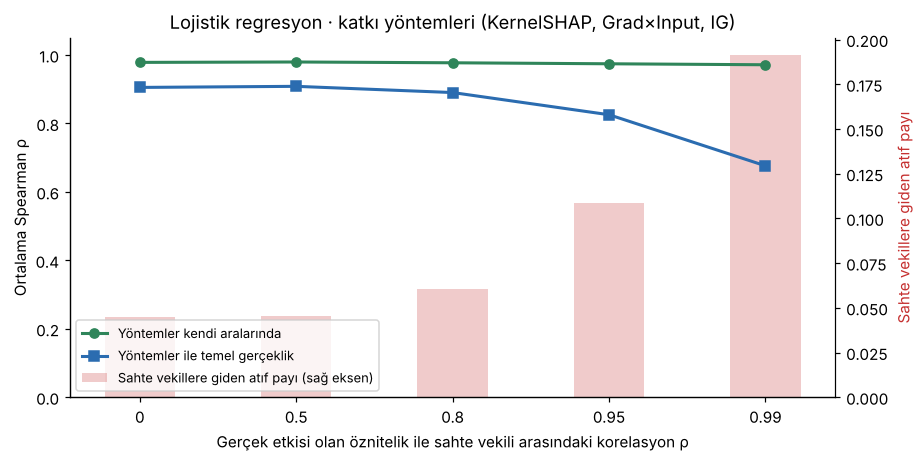

In [19]:
RHO = [0.0, 0.5, 0.8, 0.95, 0.99] if not HIZLI else [0.0, 0.8, 0.99]
KATKI = ["KernelSHAP", "Grad×Input", "IG"]
satirlar = []
for rho in RHO:
    for tekrar in range(1 if HIZLI else 3):
        X_, y_ = sentetik(1000, rho, RS + tekrar)
        a_, b_, ya_, yb_ = train_test_split(X_, y_, test_size=0.3, random_state=RS)
        lr_ = LogisticRegression(max_iter=2000).fit(a_, ya_)
        A_ = aciklamalar(lr_, b_[: AYAR["sentetik_nokta"] // 2], a_, kshap_ns=256)[0]
        U = gercege_uyum(A_, b_[: AYAR["sentetik_nokta"] // 2])
        ara = np.nanmean([uyum_matrisi({y: A_[y] for y in KATKI}, "RC", None)[0].values[np.triu_indices(3, 1)]])
        satirlar.append({"rho": rho, "Gerçekle uyum (katkı RC)": U.loc[KATKI, "Katkı RC"].mean(),
                         "Yöntemler arası uyum (RC)": ara, "Sahte vekillerin payı": U.loc[KATKI, "Sahte vekillerin payı"].mean(),
                         "Modelin sahte katsayıları |β̂6|+|β̂7|": np.abs(lr_.coef_[0][SAHTE]).sum()})
tarama = pd.DataFrame(satirlar).groupby("rho").mean()
goster(tarama.round(3))

fig, ax1 = plt.subplots(figsize=(8.5, 4.3))
xp = np.arange(len(tarama))
ax2 = ax1.twinx()
ax2.bar(xp, tarama["Sahte vekillerin payı"], width=0.45, color="#C53030", alpha=0.25, label="Sahte vekillere giden atıf payı (sağ eksen)")
ax2.set_ylabel("Sahte vekillere giden atıf payı", color="#C53030")
ax2.spines["right"].set_visible(True)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
ax1.plot(xp, tarama["Yöntemler arası uyum (RC)"], "o-", color="#2F855A", lw=2, label="Yöntemler kendi aralarında")
ax1.plot(xp, tarama["Gerçekle uyum (katkı RC)"], "s-", color="#2B6CB0", lw=2, label="Yöntemler ile temel gerçeklik")
ax1.set_xticks(xp, [f"{r:g}" for r in tarama.index])
ax1.set_xlabel("Gerçek etkisi olan öznitelik ile sahte vekili arasındaki korelasyon ρ")
ax1.set_ylabel("Ortalama Spearman ρ")
ax1.set_ylim(0, 1.05)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8.5, loc="lower left")
ax1.set_title("Lojistik regresyon · katkı yöntemleri (KernelSHAP, Grad×Input, IG)")
plt.tight_layout()
sekil_kaydet("c2-korelasyon-taramasi")
plt.show()

**Yorum (C.2).** Bu deney, Bölüm 32'deki doğruluk ile sadakat ayrımının somut bir örneği. Korelasyon arttıkça model, gerçekte
etkisi olmayan sahte vekillere ağırlık veriyor. Açıklama yöntemleri modele sadık oldukları için bu ağırlığı aynen raporluyor.
Sonuçta yöntemler **kendi aralarında uyumlu kalıyor ama hep birlikte temel gerçeklikten uzaklaşıyor**. Uyuşmazlık metrikleri bu
hatayı yakalayamaz: Herkes aynı yanlış modeli sadakatle açıklıyorsa uyum yüksek çıkar. Gerçek veride temel gerçeklik olmadığı
için bu tür bir hata ancak simülasyonla görülebilir; Bölüm 32'nin söylediği de tam olarak budur.

## 7. Bulguların özeti

Makaledeki iddiaları ve bizim sonuçlarımızı yan yana koyan tablo `makale.md` dosyasında. Aşağıdaki hücre o tablodaki sayıları
tek yerde topluyor.

In [20]:
def cift(A, y1, y2, metrik, k=5):
    return uyum_matrisi({y1: A[y1], y2: A[y2]}, metrik, k)[0].iloc[0, 1]


def ozet_sutunu(oz, A):
    return {"Çiftlerin ort. FA@5": oz.loc["FA", "Yöntem çiftleri ort."],
            "Çiftlerin ort. RA@5": oz.loc["RA", "Yöntem çiftleri ort."],
            "Çiftlerin ort. SRA@5": oz.loc["SRA", "Yöntem çiftleri ort."],
            "Çiftlerin ort. RC": oz.loc["RC", "Yöntem çiftleri ort."],
            "Şans FA@5": oz.loc["FA", "Şans düzeyi (rastgele)"],
            "Şans RA@5": oz.loc["RA", "Şans düzeyi (rastgele)"],
            "Grad–SmoothGrad RC": cift(A, "Grad", "SmoothGrad", "RC"),
            "Grad×Input–IG RC": cift(A, "Grad×Input", "IG", "RC"),
            "Grad–IG RC": cift(A, "Grad", "IG", "RC"),
            "LIME–KernelSHAP RC": cift(A, "LIME", "KernelSHAP", "RC")}


ozet = pd.DataFrame({
    "COMPAS NN": ozet_sutunu(ozet_c["NN"], A_compas["NN"]),
    "COMPAS LR": ozet_sutunu(ozet_c["LR"], A_compas["LR"]),
    "Taiwan NN": ozet_sutunu(ozet_t["NN"], A_tw["NN"]),
    "Taiwan LR": ozet_sutunu(ozet_t["LR"], A_tw["LR"]),
}).round(3)
goster(ozet)

,COMPAS NN,COMPAS LR,Taiwan NN,Taiwan LR
Çiftlerin ort. FA@5,0.877,0.888,0.455,0.653
Çiftlerin ort. RA@5,0.387,0.639,0.152,0.500
Çiftlerin ort. SRA@5,0.287,0.454,0.122,0.417
Çiftlerin ort. RC,0.731,0.885,0.395,0.821
Şans FA@5,0.713,0.713,0.206,0.215
Şans RA@5,0.145,0.142,0.042,0.044
Grad–SmoothGrad RC,0.934,1.000,0.666,1.000
Grad×Input–IG RC,0.863,1.000,0.715,1.000
Grad–IG RC,0.620,0.827,0.304,0.710
LIME–KernelSHAP RC,0.695,0.841,0.282,0.722
